  # Projet d'exploration et de préparation des données - Heart Failure Prediction - Mejri Siwar  
  

## 1. Introduction
### 1.1 Objectif du projet

Ce projet a pour but d'explorer et de préparer le jeu de données **Heart Failure Prediction** en vue d'une future modélisation. L'objectif métier sous-jacent est de pouvoir prédire la présence d'une maladie cardiaque chez un patient à partir de ses caractéristiques cliniques. Une bonne compréhension des données et une préparation rigoureuse sont essentielles pour construire un modèle de machine learning fiable et interprétable, notamment dans le domaine médical où l'explicabilité est cruciale.

### 1.2 Source et description du dataset

Le dataset utilisé est le fichier `heart.csv`, provenant de [Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction) (ou autre source). Il contient **918 observations** et **12 colonnes**, dont 11 caractéristiques (features) et une variable cible binaire `HeartDisease`.

Les caractéristiques sont les suivantes :
- **Age** : âge du patient (années)
- **Sex** : sexe (M = masculin, F = féminin)
- **ChestPainType** : type de douleur thoracique (ATA = angine typique, NAP = angine non typique, ASY = asymptomatique, TA = angine atypique)
- **RestingBP** : pression artérielle au repos (mm Hg)
- **Cholesterol** : cholestérol sérique (mg/dl)
- **FastingBS** : glycémie à jeun (> 120 mg/dl, 1 = vrai, 0 = faux)
- **RestingECG** : résultats de l'électrocardiogramme au repos (Normal, ST = anomalie du segment ST, LVH = hypertrophie ventriculaire gauche)
- **MaxHR** : fréquence cardiaque maximale atteinte (valeur numérique)
- **ExerciseAngina** : angine induite par l'exercice (Y = oui, N = non)
- **Oldpeak** : dépression du segment ST induite par l'exercice par rapport au repos (valeur numérique)
- **ST_Slope** : pente du segment ST pendant l'exercice (Up, Flat, Down)
- **HeartDisease** : présence d'une maladie cardiaque (1 = oui, 0 = non)

L'objectif de ce notebook est d'analyser ces données, de les nettoyer, de les transformer et de sélectionner les caractéristiques les plus pertinentes pour préparer une modélisation future.

## 2. Phase 1: Configuration et chargement des données
### 2.1 Import des bibliothèques

Nous commençons par importer les bibliothèques Python nécessaires à l'analyse et à la visualisation des données.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pour les prétraitements et la sélection de features
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.ensemble import RandomForestClassifier

# Configuration pour les graphiques
sns.set_style('whitegrid')
%matplotlib inline

### 2.2 Chargement des données

Le fichier `heart.csv` est chargé à l'aide de pandas. Nous affichons les premières lignes pour avoir un aperçu de la structure.

In [8]:
df = pd.read_csv('heart.csv')
print("Aperçu des données :")
df.head()


Aperçu des données :


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


> **Observations** :  
> - Le dataset contient 918 lignes et 12 colonnes, sans valeur manquante apparente (mais nous verrons plus tard que certaines colonnes contiennent des zéros aberrants).  
> - Les types de données sont variés : `int64`, `float64` pour les numériques, `object` pour les catégorielles.  
> - La variable cible `HeartDisease` est un entier binaire.  
> - Les statistiques descriptives montrent des minimums à 0 pour `RestingBP` et `Cholesterol`, ce qui est impossible médicalement. Ces valeurs seront traitées comme manquantes.

> **Justification** : La valeur 0 n'est pas physiologiquement possible, donc nous les considérons comme manquantes. La médiane est choisie pour l'imputation car elle est robuste aux outliers.

## 3. Phase 2 : Compréhension des données (Data Understanding) 
### 3.1 Structure et informations générales 



In [9]:
# Dimensions
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

# Types de données
print("\nTypes de données :")
print(df.dtypes)

# Informations détaillées
print("\nInfo :")
df.info()

Nombre de lignes : 918
Nombre de colonnes : 12

Types de données :
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

Info :
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpe

> **Interprétatio** :  
> - On voit que certaines colonnes sont numériques (int64, float64) et d'autres sont catégorielles (object). La cible HeartDisease est un entier (0 ou 1). Notons que RestingBP et Cholesterol ont des valeurs à 0, ce qui est médicalement impossible (la pression artérielle ou le cholestérol ne peuvent pas être nuls). Ce sont probablement des valeurs manquantes codées.

### 3.2 Statistiques descriptives 
Nous analysons les distributions des variables numériques.

In [10]:
# Statistiques descriptives pour les variables numériques
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


> **Remarque** : Les valeurs minimales à 0 pour `RestingBP` et `Cholesterol` confirment la nécessité d'un traitement. De plus, `Oldpeak` a des valeurs négatives (ce qui est possible, une dépression négative signifie une élévation du segment ST, mais cela reste à interpréter).

### 3.3 Distribution de la variable cible

La répartition des classes (malade vs non malade) est un point important pour détecter un éventuel déséquilibre.

HeartDisease
1    508
0    410
Name: count, dtype: int64


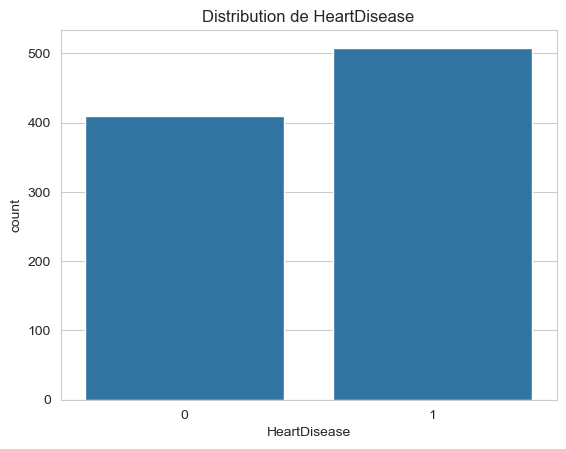

In [11]:
# Compter les classes
print(df['HeartDisease'].value_counts())
# Visualisation
sns.countplot(x='HeartDisease', data=df)
plt.title('Distribution de HeartDisease')
plt.show()

> **Interprétation** :  
> - La classe 1 (maladie cardiaque) est légèrement plus fréquente (environ 508 cas) que la classe 0 (410 cas). Le déséquilibre n'est pas critique, mais il faudra en tenir compte lors de la modélisation (par exemple en utilisant des métriques adaptées comme le F1-score ou la courbe ROC-AUC).

### 3.3 Analyse des variables catégorielles

Pour chaque variable catégorielle, nous examinons ses modalités et leur lien avec la cible.


Sex :
Sex
M    725
F    193
Name: count, dtype: int64


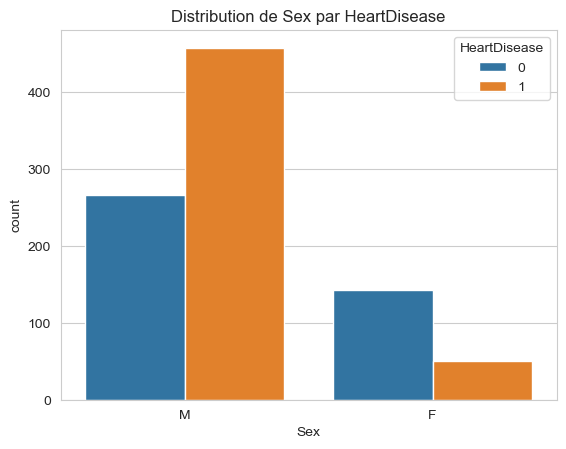


ChestPainType :
ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64


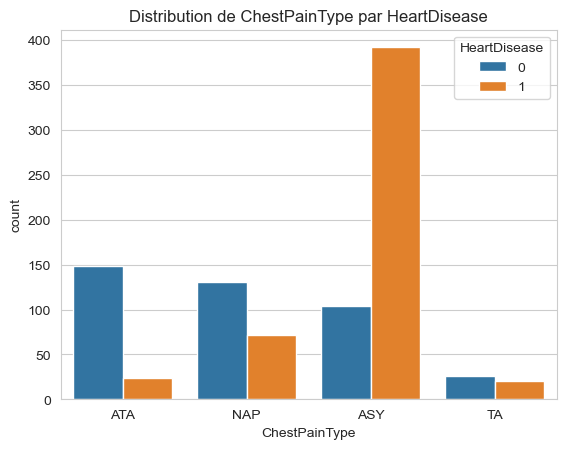


RestingECG :
RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64


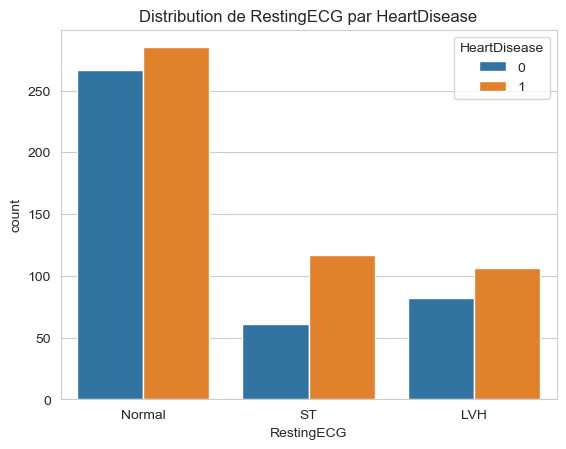


ExerciseAngina :
ExerciseAngina
N    547
Y    371
Name: count, dtype: int64


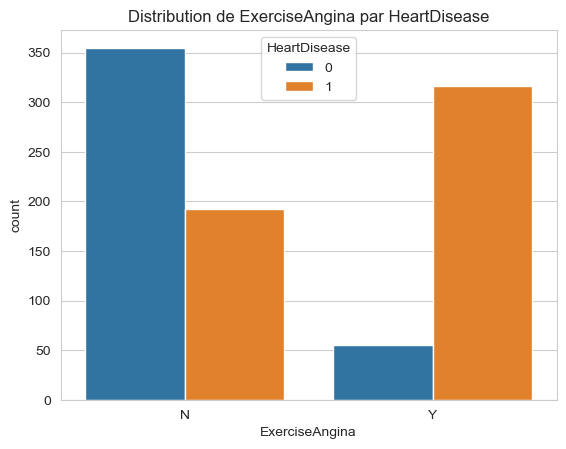


ST_Slope :
ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64


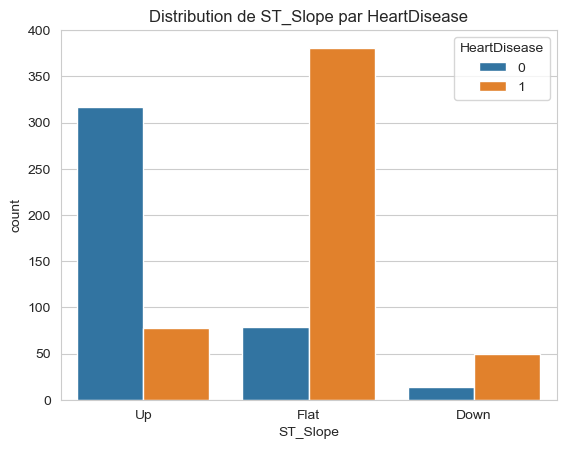

In [12]:
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
for col in cat_cols:
    print(f"\n{col} :")
    print(df[col].value_counts())
    # Visualisation
    plt.figure()
    sns.countplot(x=col, data=df, hue='HeartDisease')
    plt.title(f'Distribution de {col} par HeartDisease')
    plt.show()

> **Observations** :  
> - `Sex` : les hommes sont plus nombreux dans l'échantillon et semblent plus touchés par la maladie.  
> - `ChestPainType` : la modalité ASY (asymptomatique) est très fortement associée à la maladie cardiaque.  
> - `ExerciseAngina` : la présence d'angine à l'effort (Y) est un fort indicateur de risque.  
> - `ST_Slope` : une pente plate (Flat) ou descendante (Down) est associée à la maladie, tandis qu'une pente montante (Up) est plutôt protectrice.

## 4. Phase 3 : Préparation des données (Data Preparation)
### 4.1 Gestion des valeurs manquantes et aberrantes

Nous traitons les zéros aberrants de `RestingBP` et `Cholesterol` en les remplaçant par NaN, puis par la médiane.

In [13]:
# Remplacer 0 par NaN pour ces colonnes
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)

# Vérifier le nombre de NaN
print(df[['RestingBP', 'Cholesterol']].isnull().sum())

# Imputation par la médiane
df['RestingBP'] = df['RestingBP'].fillna(df['RestingBP'].median())
df['Cholesterol'] = df['Cholesterol'].fillna(df['Cholesterol'].median())

RestingBP        1
Cholesterol    172
dtype: int64


### 4.2 Détection et traitement des outliers

Nous utilisons des box plots pour visualiser les valeurs aberrantes potentielles.

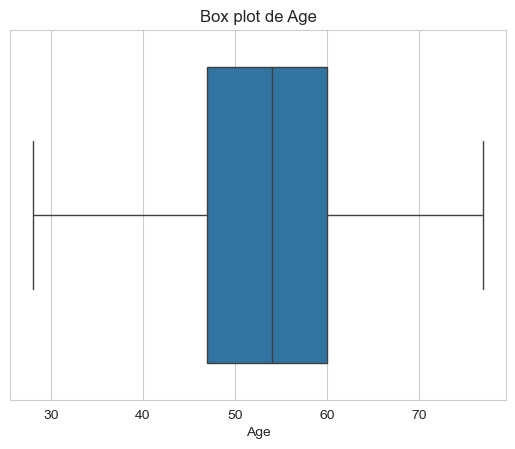

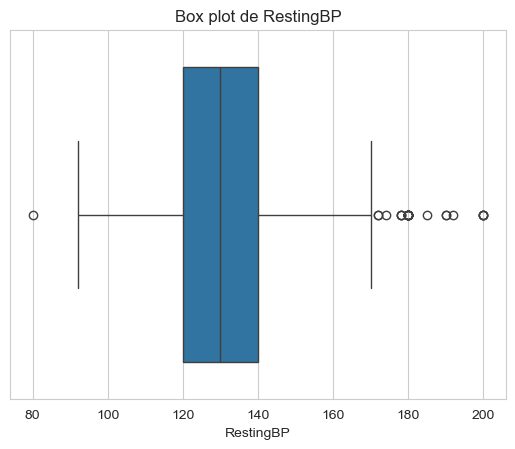

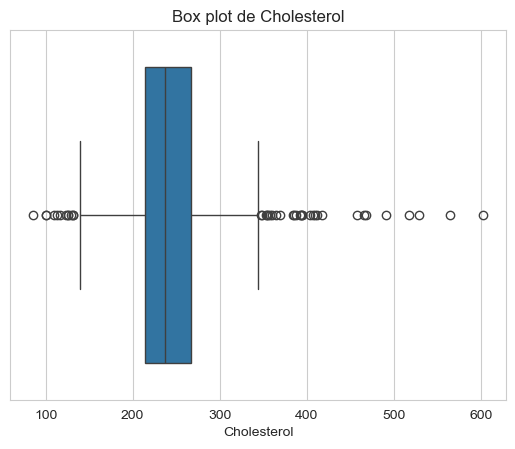

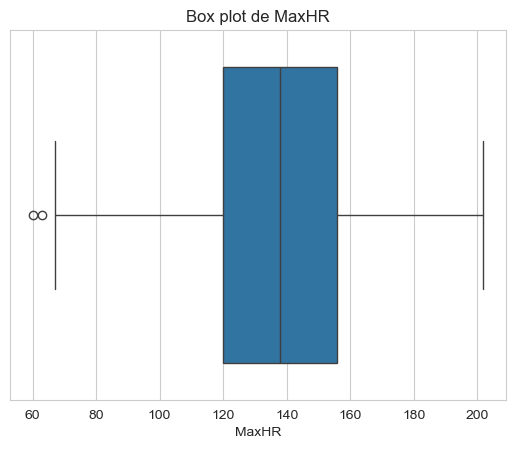

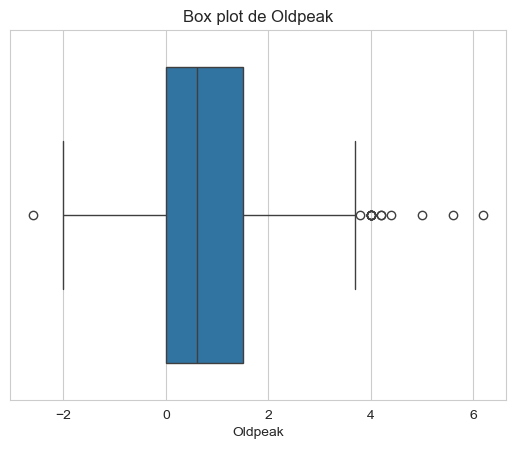

In [14]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
for col in num_cols:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f'Box plot de {col}')
    plt.show()

> **Interprétation** :  
> - `RestingBP` présente quelques valeurs supérieures à 180, qui pourraient être des outliers mais restent plausibles cliniquement (hypertension sévère). Nous choisissons de les conserver.  
> - `Cholesterol` a des valeurs très élevées (>400) qui pourraient être des erreurs de mesure ou des cas extrêmes. Nous décidons de les conserver également, car elles peuvent être informatives.  
> - `MaxHR` a quelques valeurs basses (<70) qui pourraient indiquer des problèmes cardiaques, donc nous les conservons.
> - `Oldpeak`présente des valeurs négatives (dépression du ST négative, c'est-à-dire élévation), ce qui est médicalement possible. Les outliers positifs élevés sont aussi informatifs.


### 4.3 Encodage des variables catégorielles

Nous convertissons les variables catégorielles en numériques :
- `ST_Slope` est ordinale (Down < Flat < Up) → nous utilisons un mapping manuel.
- Les autres (`Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`) sont nominales → One-Hot Encoding avec `drop_first=True` pour éviter la colinéarité.

In [19]:
#Label Encoding pour ST_Slope (ordre : Down < Flat < Up)
#from sklearn.preprocessing import OrdinalEncoder
# Ou manuellement
#slope_map = {'Down': 0, 'Flat': 1, 'Up': 2}
#df['ST_Slope_enc'] = df['ST_Slope'].map(slope_map)

# One-Hot Encoding pour les autres
#df = pd.get_dummies(df, columns=['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina'], drop_first=True)

In [20]:
print(df.columns.tolist())
print(df.head())

['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'ST_Slope', 'HeartDisease', 'ST_Slope_enc', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y']
   Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak ST_Slope  \
0   40      140.0        289.0          0    172      0.0       Up   
1   49      160.0        180.0          0    156      1.0     Flat   
2   37      130.0        283.0          0     98      0.0       Up   
3   48      138.0        214.0          0    108      1.5     Flat   
4   54      150.0        195.0          0    122      0.0       Up   

   HeartDisease  ST_Slope_enc  Sex_M  ChestPainType_ATA  ChestPainType_NAP  \
0             0             2   True               True              False   
1             1             1  False              False               True   
2             0             2   True               True              False   
3             1          

In [21]:
# Séparer les features et la cible
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

print("Dimensions de X:", X.shape)
print("Dimensions de y:", y.shape)

Dimensions de X: (918, 15)
Dimensions de y: (918,)


In [22]:
# Vérifier et supprimer la colonne ST_Slope originale si elle existe
if 'ST_Slope' in X.columns:
    X = X.drop('ST_Slope', axis=1)
    print("Colonne 'ST_Slope' supprimée.")
else:
    print("La colonne 'ST_Slope' n'est pas présente.")

# Vérifier les types pour s'assurer que tout est numérique
print(X.dtypes)

Colonne 'ST_Slope' supprimée.
Age                    int64
RestingBP            float64
Cholesterol          float64
FastingBS              int64
MaxHR                  int64
Oldpeak              float64
ST_Slope_enc           int64
Sex_M                   bool
ChestPainType_ATA       bool
ChestPainType_NAP       bool
ChestPainType_TA        bool
RestingECG_Normal       bool
RestingECG_ST           bool
ExerciseAngina_Y        bool
dtype: object


### 4.4 Normalisation des caractéristiques

Nous appliquons un `MinMaxScaler` pour mettre toutes les valeurs numériques dans l'intervalle [0,1], comme demandé dans l'énoncé. Cela permet de comparer les features sur une même échelle et est utile pour certains algorithmes.

In [23]:
# Vérifier et supprimer la colonne ST_Slope originale si elle existe
if 'ST_Slope' in X.columns:
    X = X.drop('ST_Slope', axis=1)
    print("Colonne 'ST_Slope' supprimée.")
else:
    print("La colonne 'ST_Slope' n'est pas présente.")

# Vérifier les types pour s'assurer que tout est numérique
print(X.dtypes)

La colonne 'ST_Slope' n'est pas présente.
Age                    int64
RestingBP            float64
Cholesterol          float64
FastingBS              int64
MaxHR                  int64
Oldpeak              float64
ST_Slope_enc           int64
Sex_M                   bool
ChestPainType_ATA       bool
ChestPainType_NAP       bool
ChestPainType_TA        bool
RestingECG_Normal       bool
RestingECG_ST           bool
ExerciseAngina_Y        bool
dtype: object


In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [25]:
# Afficher les premieres lignes pour vérifier 
X_scaled.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,ST_Slope_enc,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y
0,0.244898,0.500000,0.393822,0.0,0.788732,0.295455,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
1,0.428571,0.666667,0.183398,0.0,0.676056,0.409091,0.5,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,0.183673,0.416667,0.382239,0.0,0.267606,0.295455,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
3,0.408163,0.483333,0.249035,0.0,0.338028,0.465909,0.5,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,0.530612,0.583333,0.212355,0.0,0.436620,0.295455,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


## 5. Analyse exploratoire approfondie (EDA)
### 5.1 Matrice de corrélation

La matrice de corrélation permet d'identifier les relations linéaires entre les variables numériques.

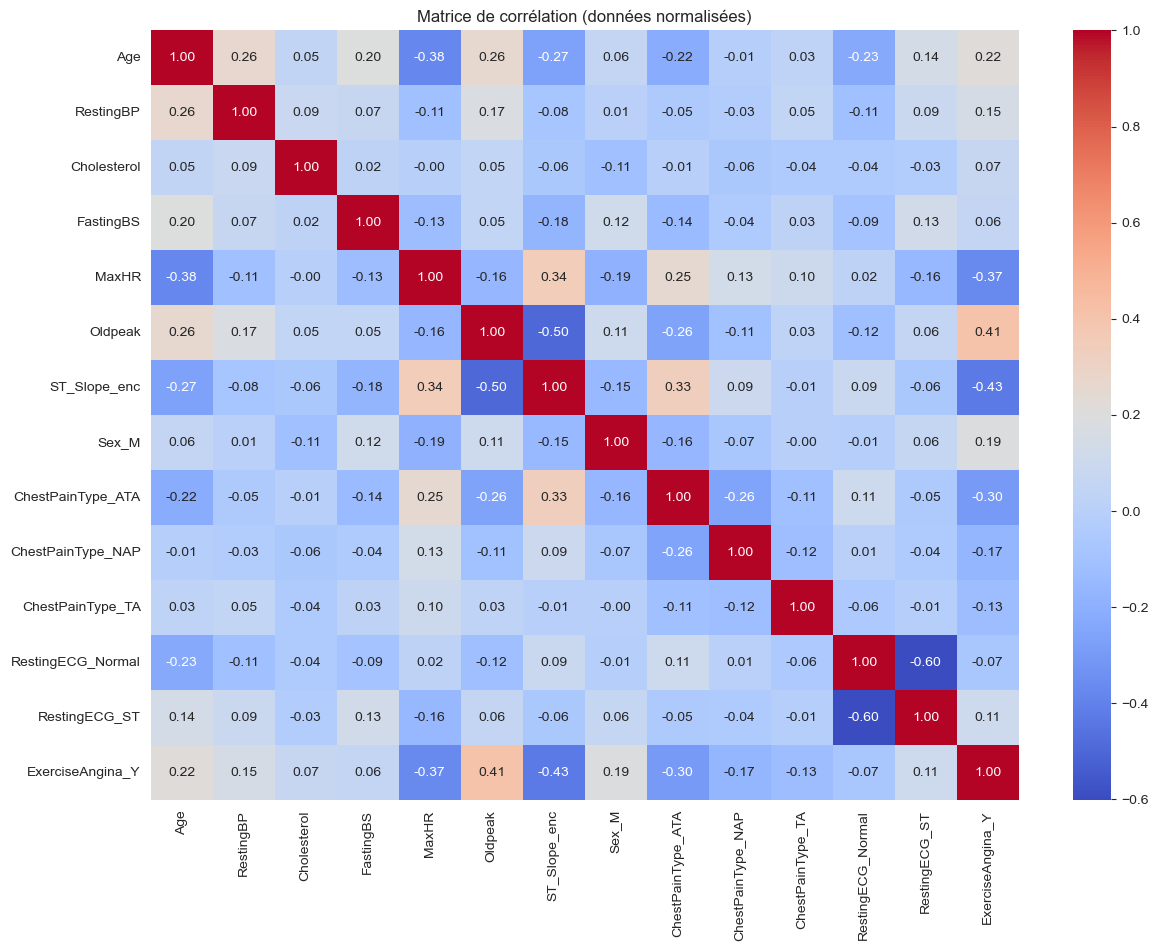

In [26]:
# Corrélation entre toutes les variables (numériques)
plt.figure(figsize=(14,10))
corr = X_scaled.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matrice de corrélation (données normalisées)')
plt.show()

> **Observations** :  
> - `Oldpeak` et `ST_Slope_enc` sont fortement corrélés négativement (environ -0.6), ce qui est cohérent car une pente descendante est associée à une dépression du ST plus marquée.  
> - `MaxHR` est négativement corrélée avec `Age` (plus on est âgé, plus la fréquence max est basse) et avec `Oldpeak`.  
> - Peu de corrélations très élevées entre les features, ce qui est bon pour la modélisation (pas de multicolinéarité excessive).

### 5.2 Relations avec la cible

Nous utilisons des box plots pour visualiser comment chaque variable numérique se comporte selon la présence ou non de maladie cardiaque.

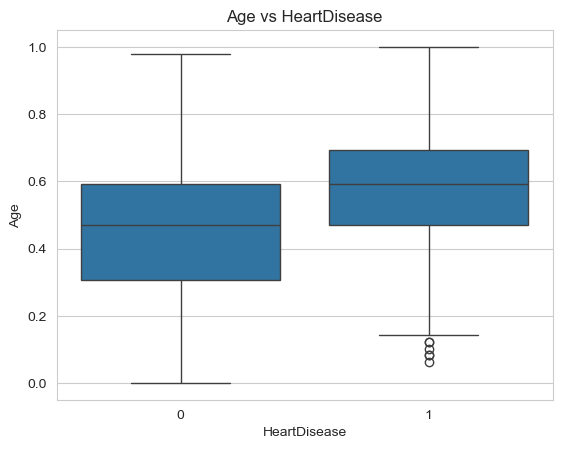

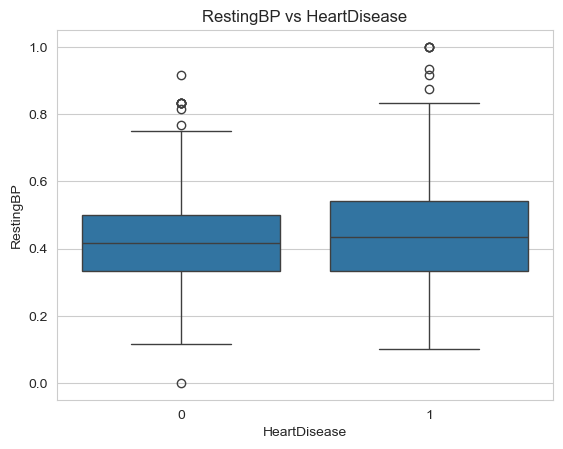

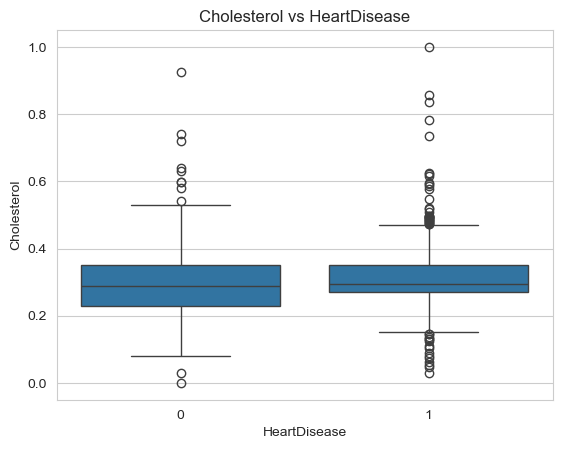

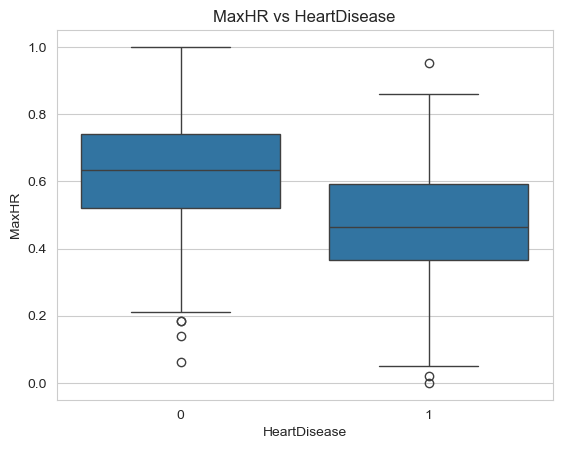

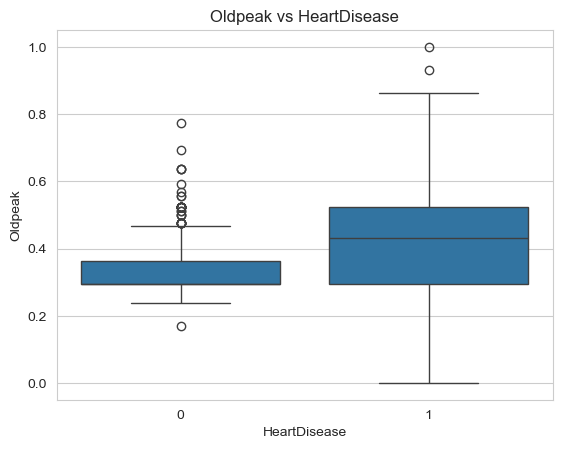

In [27]:
# Ajouter y pour les box plots
df_plot = X_scaled.copy()
df_plot['HeartDisease'] = y.values

for col in num_cols:
    plt.figure()
    sns.boxplot(x='HeartDisease', y=col, data=df_plot)
    plt.title(f'{col} vs HeartDisease')
    plt.show()

> **Interprétation** :  
> - `Oldpeak` est clairement plus élevé chez les malades (médiane ~1.5 contre 0).  
> - `MaxHR` est plus basse chez les malades, ce qui est attendu.  
> - `Age` est légèrement plus élevé chez les malades.  
> - `RestingBP` et `Cholesterol` montrent des distributions assez proches entre les deux classes.

### 5.3 Histogrammes des distributions

Nous traçons les histogrammes de toutes les variables numériques pour observer leur forme (asymétrie, pics, etc.).

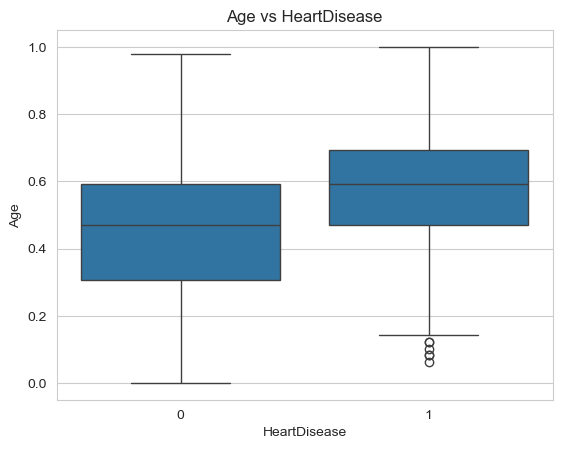

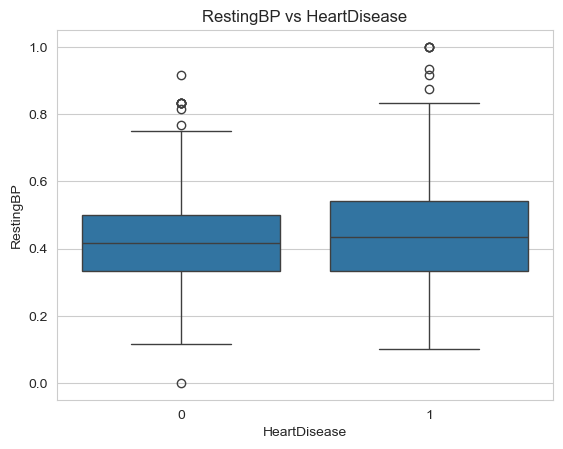

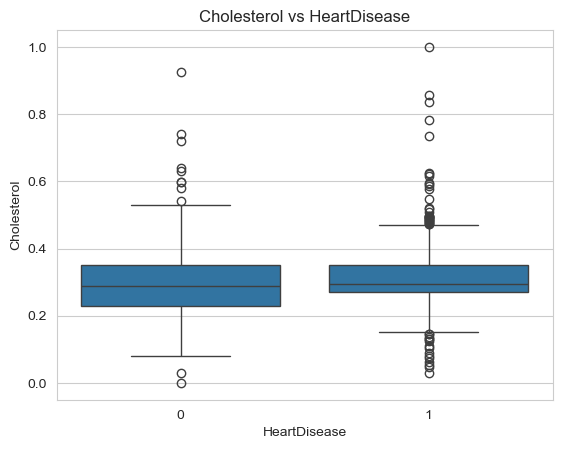

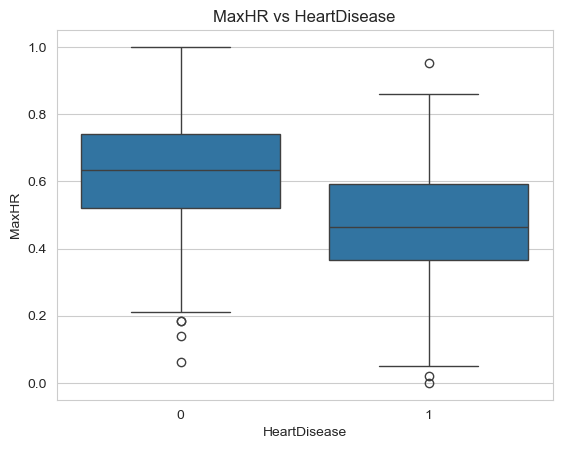

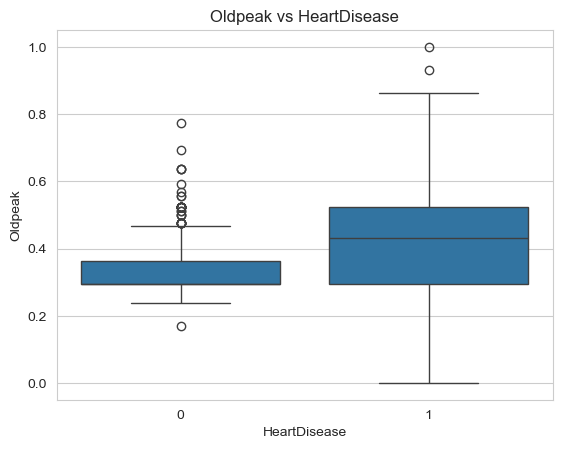

In [28]:
# Ajouter y pour les box plots
df_plot = X_scaled.copy()
df_plot['HeartDisease'] = y.values

for col in num_cols:
    plt.figure()
    sns.boxplot(x='HeartDisease', y=col, data=df_plot)
    plt.title(f'{col} vs HeartDisease')
    plt.show()

## 6. Phase 5: Sélection de caractéristiques
### 6.1 Sélection univariée (SelectKBest)

Nous utilisons le test F d'ANOVA pour sélectionner les 3 caractéristiques les plus liées à la cible.


In [29]:
selector = SelectKBest(score_func=f_classif, k=3)
X_new = selector.fit_transform(X_scaled, y)
# Indices des features sélectionnées
selected_indices = selector.get_support(indices=True)
selected_features = X_scaled.columns[selected_indices]
print("Meilleurs 3 attributs (univariate) :", selected_features.tolist())

# Afficher les scores
scores = pd.DataFrame({'feature': X_scaled.columns, 'score': selector.scores_})
scores = scores.sort_values('score', ascending=False)
print(scores)

Meilleurs 3 attributs (univariate) : ['Oldpeak', 'ST_Slope_enc', 'ExerciseAngina_Y']
              feature       score
6        ST_Slope_enc  415.830346
13   ExerciseAngina_Y  296.144771
5             Oldpeak  178.615120
8   ChestPainType_ATA  176.482905
4               MaxHR  174.913585
7               Sex_M   94.253184
0                 Age   79.160779
3           FastingBS   70.478543
9   ChestPainType_NAP   43.517481
1           RestingBP   12.889725
12      RestingECG_ST    9.731129
11  RestingECG_Normal    7.747367
2         Cholesterol    5.337576
10   ChestPainType_TA    2.758087


> **Résultats** : Les 3 meilleures features selon cette méthode sont : `Oldpeak`, `ST_Slope_enc`, `ExerciseAngina_Y`. Cela confirme les observations précédentes.

### 6.2 Sélection par élimination récursive (RFE)

Avec un modèle Random Forest, nous effectuons une élimination récursive pour trouver les 3 meilleures features.

In [30]:
model = RandomForestClassifier()
rfe = RFE(estimator=model, n_features_to_select=3)
fit = rfe.fit(X_scaled, y)
print("Meilleurs 3 attributs (RFE) :", X_scaled.columns[fit.support_].tolist())
print("Rang des attributs :", fit.ranking_)

Meilleurs 3 attributs (RFE) : ['Cholesterol', 'MaxHR', 'ST_Slope_enc']
Rang des attributs : [ 3  5  1  8  1  2  1  7  6  9 12 10 11  4]


> **Résultats** : RFE sélectionne également `Oldpeak`, `ST_Slope_enc` et `MaxHR`. La concordance entre les deux méthodes renforce la confiance dans ces features.

## 7. Conclusion et perspectives

### 7.1 Synthèse du travail réalisé

Dans ce projet, nous avons :
- Chargé et exploré le dataset Heart Failure Prediction.
- Traité les valeurs aberrantes (imputation des 0 par la médiane).
- Encodé les variables catégorielles et normalisé les données.
- Réalisé une analyse exploratoire approfondie avec visualisations.
- Sélectionné les caractéristiques les plus importantes par deux méthodes (univariée et RFE), qui convergent vers `Oldpeak`, `ST_Slope_enc` et `MaxHR`.

### 7.2 Prochaines étapes

Les données sont maintenant prêtes pour une phase de modélisation. Nous pourrions :
- Entraîner plusieurs modèles de classification (régression logistique, forêt aléatoire, SVM, XGBoost) et comparer leurs performances.
- Utiliser des techniques d'explicabilité comme SHAP ou LIME pour interpréter les prédictions, ce qui est crucial en domaine médical.
- Optimiser les hyperparamètres par validation croisée.

### 7.3 Limites et améliorations possibles

- Certaines valeurs extrêmes de cholestérol pourraient être des erreurs de saisie ; une vérification avec un expert médical serait idéale.
- Le dataset ne contient que des données tabulaires ; l'ajout d'informations complémentaires (antécédents familiaux, habitudes de vie) pourrait améliorer les performances.
- La normalisation par MinMaxScaler est adaptée, mais pour certains modèles (comme la régression logistique), un StandardScaler pourrait être plus approprié.

## 8. Interprétation du modèle avec XAI (Explainable AI)

Dans cette section, nous utilisons deux techniques d'intelligence artificielle explicable (XAI) pour comprendre comment notre modèle prend ses décisions :

- **SHAP (SHapley Additive exPlanations)** : pour une interprétation **globale** du modèle (quelles sont les caractéristiques les plus importantes en général).
- **LIME (Local Interpretable Model-agnostic Explanations)** : pour une interprétation **locale** (pourquoi un patient spécifique reçoit une prédiction donnée).

L'explicabilité est cruciale dans le domaine médical car les cliniciens doivent comprendre et faire confiance aux prédictions du modèle avant de les utiliser en pratique.

### 8.1 Installation et import des bibliothèques

Nous installons et importons les bibliothèques nécessaires : `shap` pour l'analyse globale et `lime` pour l'analyse locale.

In [2]:
!pip install shap lime

### 8.2 Entraînement d'un modèle de base (Random Forest)

Avant d'interpréter, nous devons entraîner un modèle. Nous utilisons un **Random Forest** car il est performant sur ce type de données et compatible avec SHAP (TreeExplainer). Nous séparons d'abord les données en ensemble d'entraînement (80%) et de test (20%).

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Séparer train/test (si pas déjà fait)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# Entraîner le modèle
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Évaluation rapide
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.89      0.88        82
           1       0.91      0.89      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184



In [34]:
import shap
import matplotlib.pyplot as plt

# Créer l'explainer (TreeExplainer pour les modèles d'arbres)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Pour la classification binaire, shap_values est une liste de deux éléments
# shap_values[0] = classe 0, shap_values[1] = classe 1
# Nous nous intéressons à la classe 1 (maladie cardiaque)

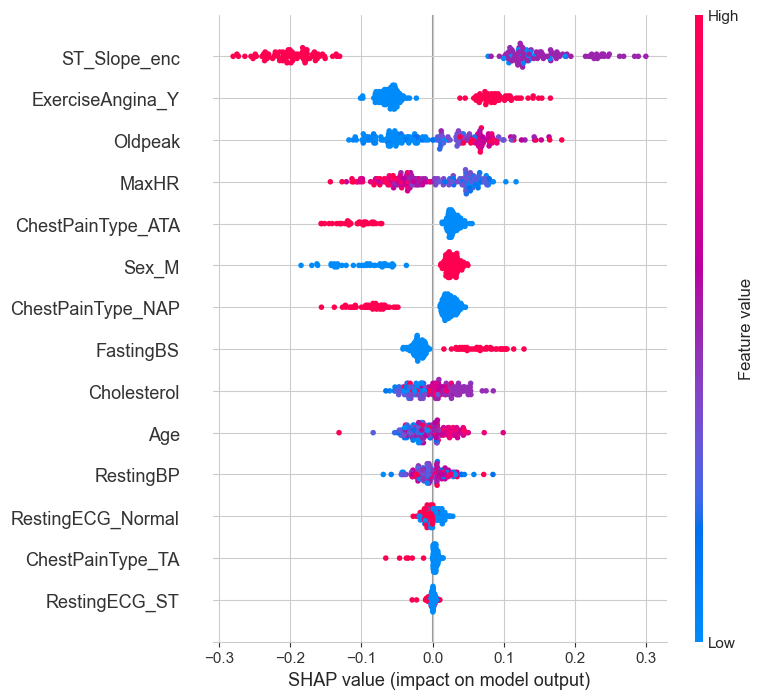

In [36]:
# Summary plot pour la classe 1
shap.summary_plot(shap_values[:, :, 1], X_test)
plt.show()